# Grover's search algorithm

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Broum/UKP_IQC_materials/blob/main/04_Qiskit_Groover.ipynb)

Content: 

## 0. Setup

Same as in `01_Qiskit_intro_colab.ipynb`: in Colab the packages are installed per session, so uncomment and re-run
this cell after every runtime restart. For a local conda environment see that notebook.
Content: 
* Manual creation of Grover algorithm by hand
* Generalized approach


In [1]:
# %pip install -q qiskit qiskit-aer pylatexenc matplotlib

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import ZGate, grover_operator
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, thermal_relaxation_error
from IPython.display import display

print(qiskit.__version__)

2.1.2


## 1. Grover's algorithm by hand

**Input:** a function $f:\{0,1\}^n\rightarrow\{0,1\}$, given as an oracle. There are $N = 2^n$ inputs.

**Promise:** $f(x) = 1$ for exactly one *marked* input $x = w$, $f(x) = 0$ otherwise (more marked inputs in section 3).

**Output:** the marked input $w$.

This is *unstructured search*: $f$ has no structure we could exploit, so classically we can only try the inputs one by one,
on average $N/2$ queries and $N - 1$ in the worst case. Grover's algorithm needs about $\frac{\pi}{4}\sqrt{N}$ queries.
That is a **quadratic** speed-up, smaller than the exponential one of Deutsch–Jozsa, but it works for every problem where
a solution is easy to *check* ($f$) but hard to *find*.

### 1.1 The oracle

The same oracle as in `03_Qiskit_Deutsch.ipynb`: $U_f\,|y\rangle|x\rangle = |y \oplus f(x)\rangle|x\rangle$ with the input $x$
on $q_0,\dots,q_{n-1}$ and the output $y$ on $q_n$. For one marked string $w$ it is a single `mcx` that fires only on $w$:
X gates on the qubits where $w$ has a 0 turn $|w\rangle$ into $|1\cdots1\rangle$ and back (as `add_cx` in 03, 3.1).

The marked string is written in the Qiskit order $q_{n-1}\dots q_1 q_0$, so it shows up in the counts under the same key.

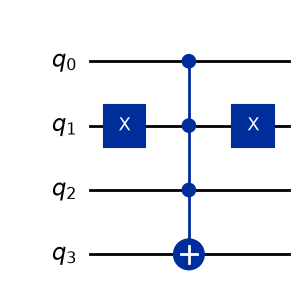

In [22]:
def grover_oracle_mcx(marked: str) -> QuantumCircuit:
    # U_f for f(x) = 1 only for x = marked; inputs q_0 ... q_{n-1}, output q_n
    n = len(marked)
    qc = QuantumCircuit(n + 1)
    zeros = [qubit for qubit, bit in enumerate(reversed(marked)) if bit == '0']
    if zeros:
        qc.x(zeros)
    qc.mcx(list(range(n)), n)
    if zeros:
        qc.x(zeros)
    return qc


marked = '101'                         # try other 3-bit strings
oracle = grover_oracle_mcx(marked)
oracle.draw('mpl')

The classical check with `truth_table` from 03, 2.1: $2^n$ queries, exactly one of them gives 1.

In [23]:
def truth_table(function: QuantumCircuit) -> dict:
    n = function.num_qubits - 1        # input qubits q_0 ... q_{n-1}, output qubit q_n
    table = {}
    for x in range(2**n):
        out = Statevector.from_int(x, 2**(n + 1)).evolve(function)
        table[f'{x:0{n}b}'] = int(np.argmax(out.probabilities())) >> n
    return table


print(truth_table(oracle))

{'000': 0, '001': 0, '010': 0, '011': 0, '100': 0, '101': 1, '110': 0, '111': 0}


### 1.2 Phase kickback: the oracle flips a sign

Start as in Deutsch–Jozsa: $H^{\otimes n}$ on the inputs gives the uniform superposition
$|s\rangle = \frac{1}{\sqrt N}\sum_x |x\rangle$, and the output qubit is in $|-\rangle$. Phase kickback (03, 2.2) gives

$$U_f\,|-\rangle|x\rangle = (-1)^{f(x)}|-\rangle|x\rangle
\qquad\Rightarrow\qquad
U_f\,|-\rangle|s\rangle = |-\rangle\otimes\frac{1}{\sqrt N}\Big(\sum_{x\neq w}|x\rangle - |w\rangle\Big)$$

The output qubit stays in $|-\rangle$ for the whole algorithm, so we only look at the $N$ amplitudes of the inputs.
The oracle flips the sign of the marked one. The probabilities $|a_x|^2$ do **not** change: measuring now would give a
uniformly random $x$, the information sits only in the phase.

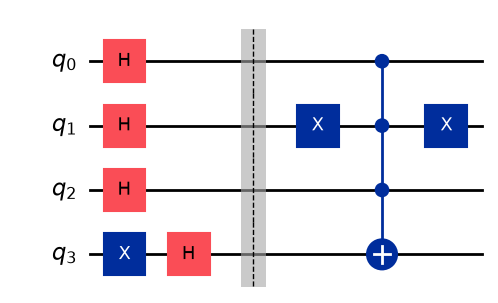

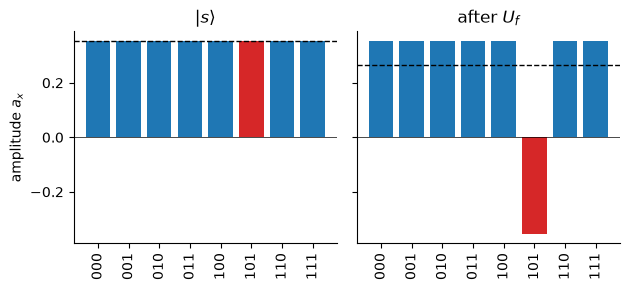

In [5]:
def input_amplitudes(qc: QuantumCircuit) -> np.ndarray:
    # Amplitudes a_x of the inputs q_0 ... q_{n-1}, assuming the output qubit q_n is in |->
    psi = Statevector(qc).data
    N = len(psi) // 2
    return ((psi[:N] - psi[N:]) / np.sqrt(2)).real   # q_n = 0 is the first half, q_n = 1 the second


def plot_amplitudes(steps: dict, marked: str):
    # One bar plot of the input amplitudes per step, the dashed line is their mean
    fig, axes = plt.subplots(1, len(steps), figsize=(3.2 * len(steps), 3), sharey=True, squeeze=False)
    for ax, (title, amps) in zip(axes[0], steps.items()):
        n = int(np.log2(len(amps)))
        labels = [f'{x:0{n}b}' for x in range(len(amps))]
        ax.bar(labels, amps, color=['tab:red' if l == marked else 'tab:blue' for l in labels])
        ax.axhline(amps.mean(), color='k', linestyle='--', linewidth=1)
        ax.axhline(0, color='k', linewidth=0.5)
        ax.set_title(title)
        ax.tick_params(axis='x', labelrotation=90)
        for side in ('top', 'right'):
            ax.spines[side].set_visible(False)
    axes[0][0].set_ylabel('amplitude $a_x$')
    plt.tight_layout()
    plt.show()


n = len(marked)
qc = QuantumCircuit(n + 1)
qc.x(n)
qc.h(range(n + 1))                     # inputs in |s>, output qubit in |->
start = input_amplitudes(qc)
qc.barrier()
qc.compose(oracle, inplace=True)

display(qc.draw('mpl'))
plot_amplitudes({r'$|s\rangle$': start, r'after $U_f$': input_amplitudes(qc)}, marked)

### 1.3 The diffuser: inversion about the mean

The second ingredient turns the sign into a measurable amplitude. The *diffuser* is

$$D = 2|s\rangle\langle s| - I, \qquad
D\sum_x a_x|x\rangle = \sum_x\left(2\bar a - a_x\right)|x\rangle, \qquad \bar a = \frac{1}{N}\sum_x a_x$$

Every amplitude is reflected about the mean $\bar a$. After the oracle the marked amplitude is negative, far below the mean,
so it is reflected high above it; all other amplitudes shrink a little. For $n = 3$:
$\bar a = \frac{6}{8}\cdot\frac{1}{\sqrt8}$, the marked amplitude goes from $-\frac{1}{\sqrt8} \approx -0.35$ to
$2\bar a + \frac{1}{\sqrt 8} \approx 0.88$.

**The circuit.** $D = H^{\otimes n}\left(2|0\cdots0\rangle\langle0\cdots0| - I\right)H^{\otimes n}$. The middle part flips the sign
of every state except $|0\cdots0\rangle$, which up to a global phase $-1$ is the same as flipping the sign of $|0\cdots0\rangle$ only.
And that is again an oracle: X gates turn $|0\cdots0\rangle$ into $|1\cdots1\rangle$ and an `mcx` onto the output qubit in $|-\rangle$
flips its sign. The gates therefore give $-D$. A global phase is not observable (02, 1.10); we set `global_phase` only so that
the plotted amplitudes have the textbook sign.

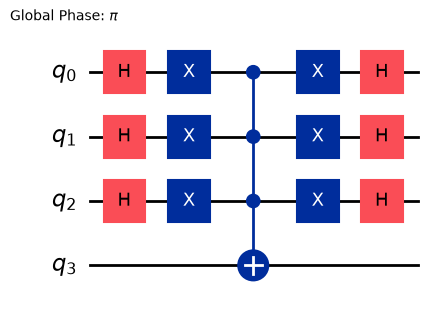

a_x after D == 2*mean - a_x before : True
marked amplitude: -0.354 -> +0.884, probability 0.781


In [6]:
def diffuser_mcx(n: int) -> QuantumCircuit:
    # D = 2|s><s| - I on the inputs q_0 ... q_{n-1}, sign flip through the output qubit q_n in |->
    qc = QuantumCircuit(n + 1)
    qc.h(range(n))
    qc.x(range(n))
    qc.mcx(list(range(n)), n)
    qc.x(range(n))
    qc.h(range(n))
    qc.global_phase = np.pi            # the gates give -D, try removing this line
    return qc


diffuser = diffuser_mcx(n)
display(diffuser.draw('mpl'))

before = input_amplitudes(qc)
qc.barrier()
qc.compose(diffuser, inplace=True)
after = input_amplitudes(qc)

print('a_x after D == 2*mean - a_x before :', np.allclose(after, 2 * before.mean() - before))
print(f'marked amplitude: {before[int(marked, 2)]:+.3f} -> {after[int(marked, 2)]:+.3f}, '
      f'probability {after[int(marked, 2)]**2:.3f}')

### 1.4 Grover iterations

One *Grover iteration* is $G = D\,U_f$. Each iteration moves more amplitude to $|w\rangle$, so we repeat it.
Watch the red bar during two iterations.

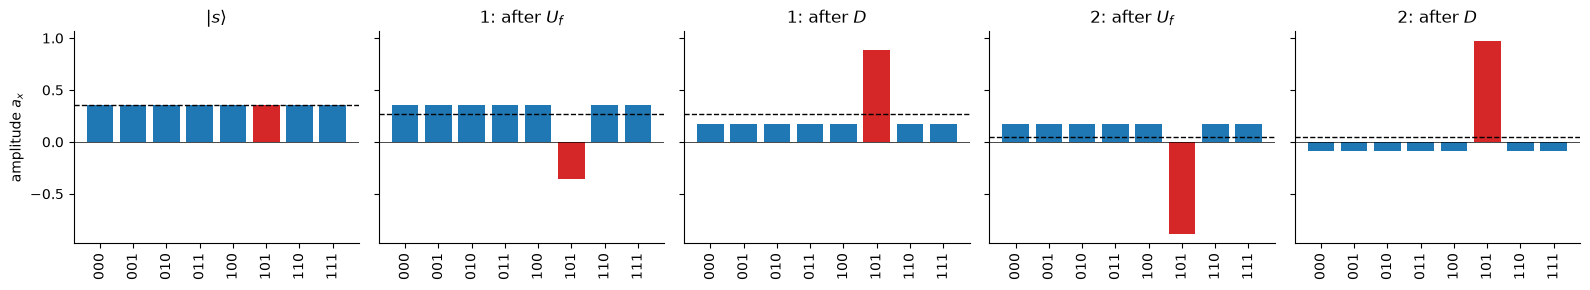

In [7]:
iterations = 2                         # try 3, 4, 5: the red bar shrinks again

qc = QuantumCircuit(n + 1)
qc.x(n)
qc.h(range(n + 1))
steps = {r'$|s\rangle$': input_amplitudes(qc)}
for k in range(1, iterations + 1):
    qc.compose(oracle, inplace=True)
    steps[rf'{k}: after $U_f$'] = input_amplitudes(qc)
    qc.compose(diffuser, inplace=True)
    steps[rf'{k}: after $D$'] = input_amplitudes(qc)

plot_amplitudes(steps, marked)

### 1.5 Run it

The whole circuit: $X$ and $H$ on the output qubit, $H^{\otimes n}$ on the inputs, the Grover iteration repeated, measure the inputs.

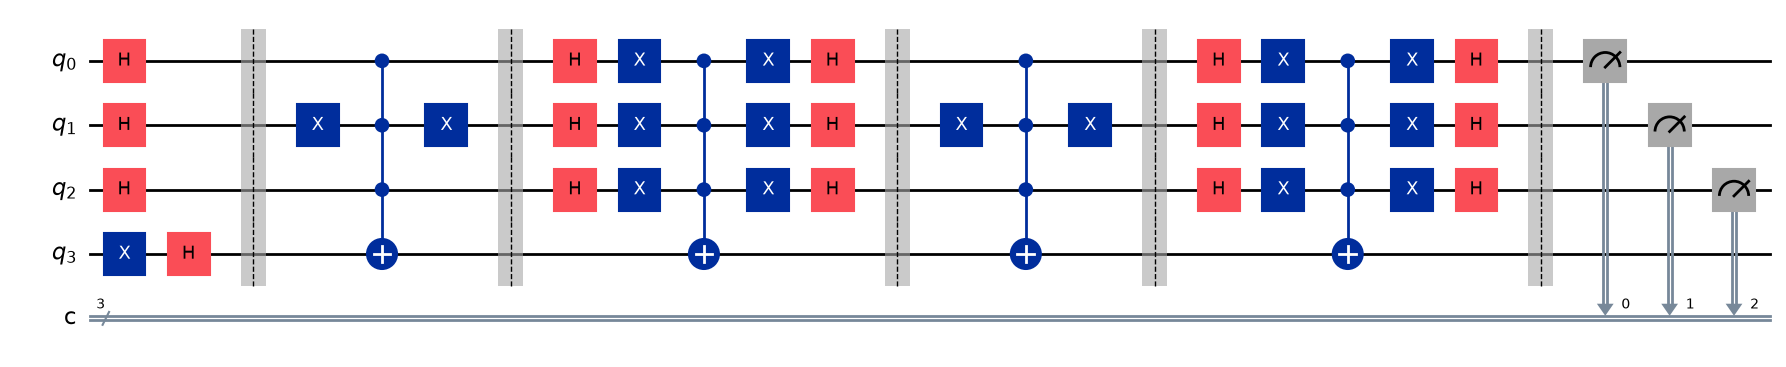

In [8]:
def grover_by_hand(marked: str, iterations: int) -> QuantumCircuit:
    n = len(marked)
    oracle, diffuser = grover_oracle_mcx(marked), diffuser_mcx(n)
    qc = QuantumCircuit(n + 1, n)
    qc.x(n)
    qc.h(range(n + 1))
    for _ in range(iterations):
        qc.barrier()
        qc.compose(oracle, inplace=True)
        qc.barrier()
        qc.compose(diffuser, inplace=True)
    qc.barrier()
    qc.measure(range(n), range(n))
    return qc


qc = grover_by_hand(marked, iterations=2)
qc.draw('mpl', fold=-1)

1 iteration(s): P(101) = 0.780
2 iteration(s): P(101) = 0.948


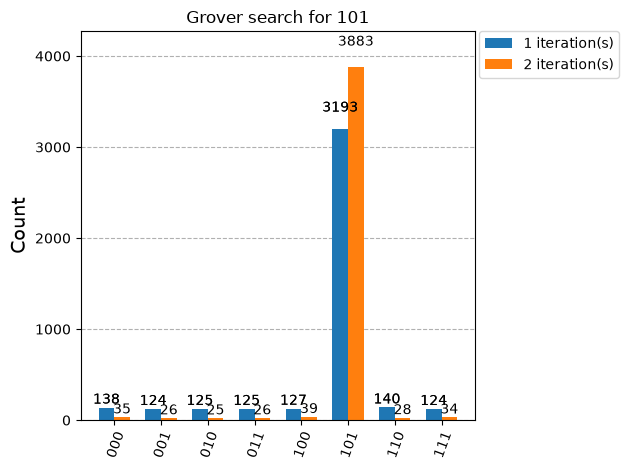

In [9]:
shots = 4096
sim = AerSimulator()

results = {}
for k in [1, 2]:
    qc = grover_by_hand(marked, iterations=k)
    results[f'{k} iteration(s)'] = sim.run(transpile(qc, sim), shots=shots).result().get_counts()
    print(f'{k} iteration(s): P({marked}) = {results[f"{k} iteration(s)"].get(marked, 0) / shots:.3f}')

plot_histogram(list(results.values()), legend=list(results.keys()), title=f'Grover search for {marked}')

With 2 iterations the marked string comes out in about 95 % of the shots. It is not 100 %: Grover's algorithm is probabilistic,
but we can check the answer with one more classical query of $f$ and repeat if it is wrong.

## 2. How many iterations?

### 2.1 The geometric picture

Split $|s\rangle$ into the marked state and the uniform superposition of the unmarked ones,
$|s'\rangle = \frac{1}{\sqrt{N-1}}\sum_{x\neq w}|x\rangle$:

$$|s\rangle = \sin\theta\,|w\rangle + \cos\theta\,|s'\rangle, \qquad \sin\theta = \frac{1}{\sqrt N}$$

Both $U_f$ and $D$ are reflections in the plane spanned by $|w\rangle$ and $|s'\rangle$: $U_f$ about $|s'\rangle$, $D$ about $|s\rangle$.
Two reflections are a rotation by twice the angle between the mirrors, so every iteration rotates the state by $2\theta$ towards $|w\rangle$:

$$G^k|s\rangle = \sin\big((2k+1)\theta\big)\,|w\rangle + \cos\big((2k+1)\theta\big)\,|s'\rangle, \qquad
P_k(w) = \sin^2\big((2k+1)\theta\big)$$

The probability is largest for $(2k+1)\theta \approx \frac{\pi}{2}$, i.e. after

$$k_\text{opt} = \left\lfloor \frac{\pi}{4\theta} \right\rfloor \approx \frac{\pi}{4}\sqrt N \text{ iterations.}$$

**More iterations are not better:** after $k_\text{opt}$ the state rotates past $|w\rangle$ and the probability drops again.

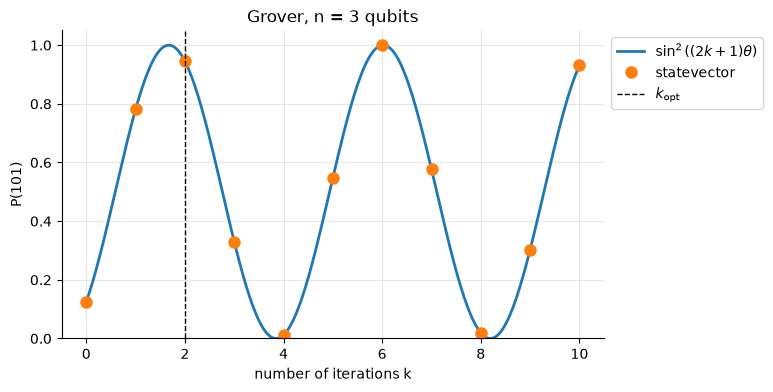

In [10]:
def optimal_iterations(n: int, num_marked: int = 1) -> int:
    theta = math.asin(math.sqrt(num_marked / 2**n))
    return math.floor(math.pi / (4 * theta))


def success_probability(marked: str, iterations: int) -> float:
    # Exact probability of measuring the marked string, from the statevector
    qc = grover_by_hand(marked, iterations).remove_final_measurements(inplace=False)
    probs = Statevector(qc).probabilities_dict(qargs=range(len(marked)))
    return probs.get(marked, 0)


ks = range(0, 11)
theta = math.asin(1 / math.sqrt(2**n))
k_fine = np.linspace(0, max(ks), 300)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k_fine, np.sin((2 * k_fine + 1) * theta)**2, linewidth=2, label=r'$\sin^2((2k+1)\theta)$')
ax.plot(ks, [success_probability(marked, k) for k in ks], 'o', markersize=8, label='statevector')
ax.axvline(optimal_iterations(n), color='k', linestyle='--', linewidth=1, label=r'$k_\mathrm{opt}$')
ax.set_ylim(0, 1.05)
ax.set_xlabel('number of iterations k')
ax.set_ylabel(f'P({marked})')
ax.set_title(f'Grover, n = {n} qubits')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
ax.grid(alpha=0.3)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.show()

### 2.2 The quadratic speed-up

Queries needed by Grover ($k_\text{opt}$) and by a classical search (on average $N/2$), for growing $n$.
For $n = 2$ one iteration finds $w$ with certainty.

In [11]:
print(' n |       N | Grover k_opt | P_success | classical, average N/2')
for n_ in range(2, 21, 2):
    N = 2**n_
    k = optimal_iterations(n_)
    p = math.sin((2 * k + 1) * math.asin(1 / math.sqrt(N)))**2
    print(f'{n_:2d} | {N:7d} | {k:12d} | {p:9.4f} | {N // 2:7d}')

 n |       N | Grover k_opt | P_success | classical, average N/2
 2 |       4 |            1 |    1.0000 |       2
 4 |      16 |            3 |    0.9613 |       8
 6 |      64 |            6 |    0.9966 |      32
 8 |     256 |           12 |    0.9999 |     128
10 |    1024 |           25 |    0.9995 |     512
12 |    4096 |           50 |    0.9999 |    2048
14 |   16384 |          100 |    1.0000 |    8192
16 |   65536 |          201 |    1.0000 |   32768
18 |  262144 |          402 |    1.0000 |  131072
20 | 1048576 |          804 |    1.0000 |  524288


## 3. A general Grover circuit

### 3.1 A phase oracle, more marked states

The output qubit in $|-\rangle$ was only a trick to turn a bit flip into a sign flip. We can flip the sign directly with a
*phase oracle*

$$Z_f\,|x\rangle = (-1)^{f(x)}|x\rangle$$

For one marked string it is a multi-controlled Z (MCZ) with X gates around it. MCZ multiplies only $|1\cdots1\rangle$ by $-1$,
so it does not matter which qubit we call the target. With several marked strings we add one such block per string: each block
flips the sign of its own string and does nothing to the others. This saves the output qubit.

With $M$ marked states everything from section 2 still holds with $\sin\theta = \sqrt{M/N}$, so
$k_\text{opt} = \left\lfloor \frac{\pi}{4\theta}\right\rfloor \approx \frac{\pi}{4}\sqrt{N/M}$.

Source: [IBM Quantum Platform, Grover's algorithm tutorial](https://quantum.cloud.ibm.com/docs/en/tutorials/grover-algorithm)

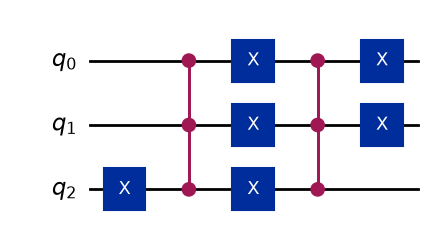

In [12]:
def grover_oracle(marked_states: list[str]) -> QuantumCircuit:
    # Phase oracle Z_f: flips the sign of every marked string, no output qubit
    num_qubits = len(marked_states[0])
    qc = QuantumCircuit(num_qubits)
    mcz = ZGate().control(num_qubits - 1)
    for target in marked_states:
        zeros = [qubit for qubit, bit in enumerate(reversed(target)) if bit == '0']
        if zeros:
            qc.x(zeros)
        qc.append(mcz, range(num_qubits))
        if zeros:
            qc.x(zeros)
    return qc


marked_states = ['011', '100']         # try ['100'], ['0110'], ['00111', '11000'], ...
oracle = grover_oracle(marked_states)
oracle.draw('mpl')

$Z_f$ is a diagonal matrix with $-1$ exactly at the marked strings:

In [13]:
n = oracle.num_qubits
diagonal = np.diag(Operator(oracle).data).real
print({f'{x:0{n}b}': int(round(d)) for x, d in enumerate(diagonal)})

{'000': 1, '001': 1, '010': 1, '011': -1, '100': -1, '101': 1, '110': 1, '111': 1}


### 3.2 The Grover operator in Qiskit

`grover_operator(oracle)` builds the whole iteration $G = D\,Z_f$, including the diffuser. (Older tutorials use the class
`GroverOperator`, which is deprecated since Qiskit 2.1.) In the drawing: first the oracle, then the diffuser from 1.3, with an MCZ
in place of the `mcx` onto the output qubit. Qiskit writes this MCZ as $H\,$`mcx`$\,H$ on the last qubit, since $HXH = Z$.

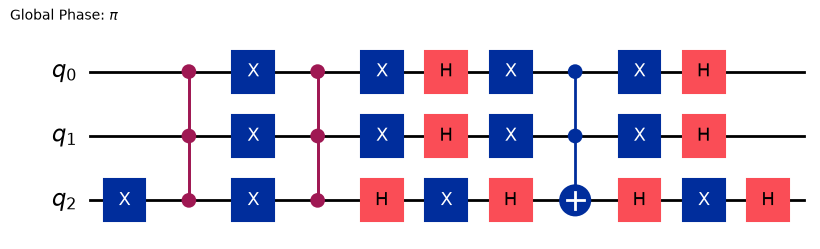

In [14]:
grover_op = grover_operator(oracle)
grover_op.draw('mpl')

### 3.3 Run it

optimal number of iterations: 1


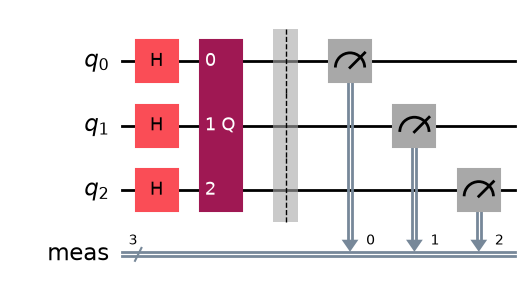

In [15]:
def grover_circuit(marked_states: list[str], iterations: int | None = None) -> QuantumCircuit:
    oracle = grover_oracle(marked_states)
    n = oracle.num_qubits
    if iterations is None:
        iterations = optimal_iterations(n, len(marked_states))
    qc = QuantumCircuit(n)
    qc.h(range(n))                     # uniform superposition |s>
    qc.compose(grover_operator(oracle).power(iterations), inplace=True)
    qc.measure_all()
    return qc


print('optimal number of iterations:', optimal_iterations(n, len(marked_states)))
qc = grover_circuit(marked_states)
qc.draw('mpl')

{'011': 2043, '100': 2053}
P(marked) = 1.000


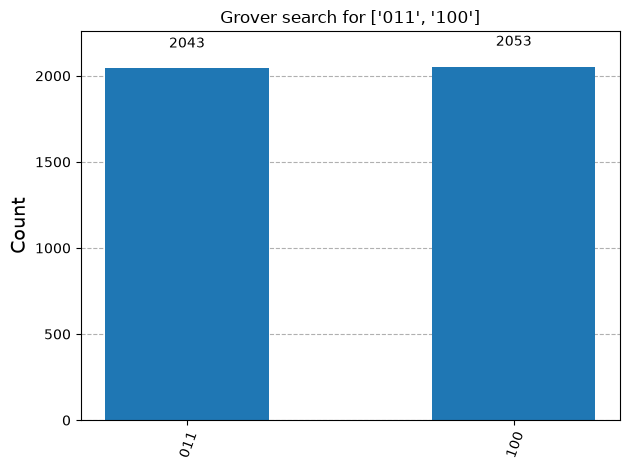

In [16]:
counts = sim.run(transpile(qc, sim), shots=shots).result().get_counts()
p_marked = sum(counts.get(s, 0) for s in marked_states) / shots

print(counts)
print(f'P(marked) = {p_marked:.3f}')
plot_histogram(counts, title=f'Grover search for {marked_states}')

For $M = 2$ out of $N = 8$: $\sin\theta = \frac12$, $\theta = \frac{\pi}{6}$, and one iteration gives
$\sin^2\left(3\cdot\frac{\pi}{6}\right) = 1$. The two marked strings come out with equal probability, never anything else.

## 4. Grover on the noisy simulator

### 4.1 The noise model

The same model as in 03, 1.3 (typical numbers for superconducting qubits). As there, we transpile into `basis_gates` before
the noisy run, otherwise the `mcx` and `mcz` gates would run without noise.

In [17]:
# Coherence and gate times
T1 = 80e-6                             # 80 µs
T2 = 60e-6                             # 60 µs
t_1q = 35e-9                           # 35 ns
t_2q = 250e-9                          # 250 ns

# Depolarising probabilities
p_1q = 1.0e-3
p_2q = 1.5e-2

# Readout error (symmetric)
p_ro = 0.02

noise_model = NoiseModel()

# 1q: thermal relaxation followed by depolarisation
err_1q = thermal_relaxation_error(T1, T2, t_1q).compose(depolarizing_error(p_1q, 1))

# 2q (CX): thermal relaxation on both qubits followed by 2-qubit depolarisation
relax_2q = thermal_relaxation_error(T1, T2, t_2q).tensor(thermal_relaxation_error(T1, T2, t_2q))
err_2q = relax_2q.compose(depolarizing_error(p_2q, 2))

oneq_gates = ['id', 'x', 'y', 'z', 'h', 'sx', 'rx', 'ry', 'rz']
noise_model.add_all_qubit_quantum_error(err_1q, oneq_gates)
noise_model.add_all_qubit_quantum_error(err_2q, ['cx'])

# Readout: row = prepared bit, column = measured bit
noise_model.add_all_qubit_readout_error([[1 - p_ro, p_ro], [p_ro, 1 - p_ro]])

basis_gates = ['cx', 'x', 'sx', 'rz', 'h']
noisy_sim = AerSimulator(noise_model=noise_model)


def run_noisy(qc, shots=shots):
    tqc = transpile(qc, basis_gates=basis_gates)
    return noisy_sim.run(tqc, shots=shots).result().get_counts()

### 4.2 Ideal vs. noisy

The circuit from 3.3. The marked strings still stand out, but other strings appear as well.

CX gates after transpilation: 18
P(marked): ideal 1.000, noisy 0.711


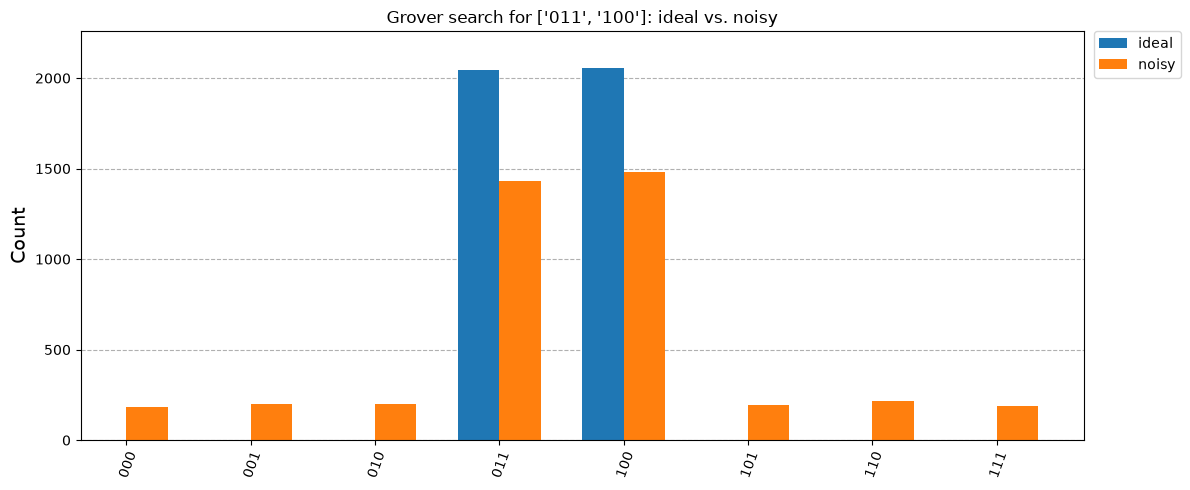

In [18]:
counts_noisy = run_noisy(qc)
p_noisy = sum(counts_noisy.get(s, 0) for s in marked_states) / shots

print(f'CX gates after transpilation: {transpile(qc, basis_gates=basis_gates).count_ops().get("cx", 0)}')
print(f'P(marked): ideal {p_marked:.3f}, noisy {p_noisy:.3f}')
plot_histogram([counts, counts_noisy], legend=['ideal', 'noisy'],
               title=f'Grover search for {marked_states}: ideal vs. noisy', figsize=(12, 5), bar_labels=False)

### 4.3 Bigger searches are more fragile

One marked string, growing $n$. Two things grow at once: the number of iterations ($\approx\frac{\pi}{4}\sqrt{2^n}$) and the number
of CNOTs in every MCZ. Compare the success probability with a random guess, $1/N$: once the noisy curve reaches it, the algorithm
is no better than guessing. (The cell runs for a few seconds.)

n = 2: 1 iteration(s),    2 CX | P ideal 1.000, noisy 0.921, guess 0.250
n = 3: 2 iteration(s),   24 CX | P ideal 0.946, noisy 0.572, guess 0.125
n = 4: 3 iteration(s),   84 CX | P ideal 0.962, noisy 0.225, guess 0.062
n = 5: 4 iteration(s),  288 CX | P ideal 0.999, noisy 0.035, guess 0.031
n = 6: 6 iteration(s),  986 CX | P ideal 0.998, noisy 0.016, guess 0.016


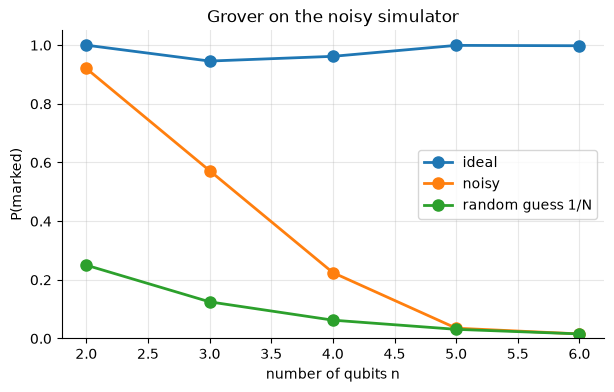

In [19]:
ns = range(2, 7)
rows = []
for n_ in ns:
    target = ('10' * n_)[:n_]
    qc_n = grover_circuit([target])
    cx = transpile(qc_n, basis_gates=basis_gates).count_ops().get('cx', 0)
    ideal = sim.run(transpile(qc_n, sim), shots=shots).result().get_counts().get(target, 0) / shots
    noisy = run_noisy(qc_n).get(target, 0) / shots
    rows.append((ideal, noisy, 1 / 2**n_))
    print(f'n = {n_}: {optimal_iterations(n_)} iteration(s), {cx:4d} CX | P ideal {ideal:.3f}, noisy {noisy:.3f}, guess {1 / 2**n_:.3f}')

fig, ax = plt.subplots(figsize=(7, 4))
for values, label in zip(zip(*rows), ['ideal', 'noisy', 'random guess 1/N']):
    ax.plot(ns, values, marker='o', markersize=8, linewidth=2, label=label)
ax.set_ylim(0, 1.05)
ax.set_xlabel('number of qubits n')
ax.set_ylabel('P(marked)')
ax.set_title('Grover on the noisy simulator')
ax.legend()
ax.grid(alpha=0.3)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.show()

**Questions**

- For $n = 3$ and one marked string, is 1 or 2 iterations better on the noisy simulator? (Use `grover_circuit(['101'], iterations=k)`.)
- Mark half of all strings, e.g. every string with $q_0 = 1$. What does one Grover iteration do, and why? (Hint: $\theta$.)
- $k_\text{opt}$ needs the number $M$ of marked strings. What could you do if $M$ is unknown?
- Which of the noise parameters in 4.1 limits the size of the search the most?